In [1]:
import json
from pathlib import Path

notebook_path = Path.cwd() / "02_Clustering_Analysis.ipynb"

with open(notebook_path, "r", encoding="utf-8") as f:
    notebook = json.load(f)

for i, cell in enumerate(notebook["cells"]):
    if cell["cell_type"] == "code":
        code = "".join(cell["source"])

        if any(term in code for term in [
            "project_folder",
            "read_csv",
            "to_csv",
            "savefig",
            "map_boundaries"
        ]):
            print(f"\n--- CELL {i} ---")
            print(code)


--- CELL 0 ---
import json
from pathlib import Path

notebook_path = Path.cwd() / "02_Clustering_Analysis.ipynb"

with open(notebook_path, "r", encoding="utf-8") as f:
    notebook = json.load(f)

for i, cell in enumerate(notebook["cells"]):
    if cell["cell_type"] == "code":
        code = "".join(cell["source"])

        if any(term in code for term in [
            "project_folder",
            "read_csv",
            "to_csv",
            "savefig",
            "map_boundaries"
        ]):
            print(f"\n--- CELL {i} ---")
            print(code)

--- CELL 1 ---
from pathlib import Path

# Main project directory
PROJECT_DIR = Path.cwd().parent

# Project subdirectories
DATA_DIR = PROJECT_DIR / "data" / "processed"
RESULTS_DIR = PROJECT_DIR / "results"
RAW_DIR = PROJECT_DIR / "data" / "raw"
BOUNDARIES_DIR = PROJECT_DIR / "map_boundaries"
NOTEBOOKS_DIR = PROJECT_DIR / "notebooks"

# Verify directories
print("Project:", PROJECT_DIR)
print("Processed data:", DATA_DIR.exists())

In [2]:
from pathlib import Path

# Main project directory
PROJECT_DIR = Path.cwd().parent

# Project subdirectories
DATA_DIR = PROJECT_DIR / "data" / "processed"
RESULTS_DIR = PROJECT_DIR / "results"
RAW_DIR = PROJECT_DIR / "data" / "raw"
BOUNDARIES_DIR = PROJECT_DIR / "map_boundaries"
NOTEBOOKS_DIR = PROJECT_DIR / "notebooks"

# Verify directories
print("Project:", PROJECT_DIR)
print("Processed data:", DATA_DIR.exists())
print("Results:", RESULTS_DIR.exists())
print("Raw data:", RAW_DIR.exists())
print("Map boundaries:", BOUNDARIES_DIR.exists())

Project: c:\Users\Hp\OneDrive\Desktop\Regional Pollution Hotspot Profiles from Satellite-Derived Environmental Features
Processed data: True
Results: True
Raw data: True
Map boundaries: True


In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, davies_bouldin_score

In [4]:
final_0530 = pd.read_csv(
    DATA_DIR / "final_regional_dataset_0530.csv"
)

print("Shape:", final_0530.shape)
print("\nColumns:")
print(final_0530.columns.tolist())

Shape: (430, 19)

Columns:
['latitude', 'longitude', 'time', 'AOD_mean', 'AOD_median', 'AOD_std', 'AOD_count', 'LST_mean', 'LST_median', 'LST_std', 'LST_count', 'Rainfall_mean', 'Rainfall_median', 'Rainfall_max', 'Rainfall_std', 'Rainfall_count', 'Rainfall_positive_pct', 'Smoke_count', 'Fire_count']


In [5]:
final_0530.head()
final_0530.isnull().sum()

latitude                 0
longitude                0
time                     0
AOD_mean                 0
AOD_median               0
AOD_std                  0
AOD_count                0
LST_mean                 0
LST_median               0
LST_std                  0
LST_count                0
Rainfall_mean            0
Rainfall_median          0
Rainfall_max             0
Rainfall_std             0
Rainfall_count           0
Rainfall_positive_pct    0
Smoke_count              0
Fire_count               0
dtype: int64

In [6]:
cluster_features = [
    "AOD_mean",
    "LST_mean"
]

x = final_0530[cluster_features].copy()

print("Clustering features:", cluster_features)
print("Shape:", x.shape)

Clustering features: ['AOD_mean', 'LST_mean']
Shape: (430, 2)


In [7]:

scaler = StandardScaler()

x_scaled = scaler.fit_transform(x)

x_scaled = pd.DataFrame(
    x_scaled,
    columns=cluster_features,
    index=x.index
)

x_scaled.describe()

,AOD_mean,LST_mean
count,4.300000e+02,4.300000e+02
mean,-1.239319e-16,-1.677211e-15
std,1.001165e+00,1.001165e+00
min,-1.234534e+00,-3.940357e+00
25%,-6.578653e-01,-7.169377e-01
50%,-2.902788e-01,-1.689212e-03
75%,3.180646e-01,7.009136e-01
max,5.587575e+00,3.025467e+00


In [8]:

k_values = range(2, 11)

wcss = []

for k in k_values:
    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )
    
    kmeans.fit(x_scaled)
    
    wcss.append(kmeans.inertia_)

print("K values:", list(k_values))
print("WCSS values:", wcss)

K values: [2, 3, 4, 5, 6, 7, 8, 9, 10]
WCSS values: [506.60787889747974, 329.5956357638844, 267.54770838369484, 225.98409941922313, 191.07769908469783, 163.0805575299786, 136.74518275549786, 113.80513710923142, 104.16212761656743]


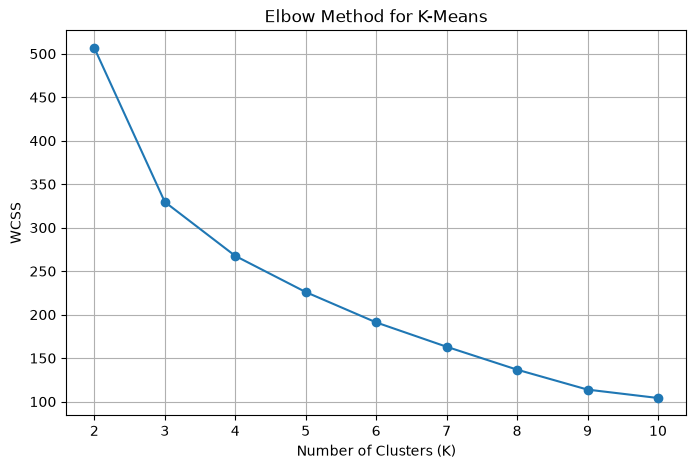

In [9]:

plt.figure(figsize=(8, 5))

plt.plot(
    k_values,
    wcss,
    marker="o"
)

plt.xlabel("Number of Clusters (K)")
plt.ylabel("WCSS")
plt.title("Elbow Method for K-Means")

plt.xticks(list(k_values))
plt.grid(True)

plt.show()

In [10]:

silhouette_scores = []
davies_bouldin_scores = []

for k in k_values:
    
    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )
    
    cluster_labels = kmeans.fit_predict(x_scaled)
    
    silhouette_scores.append(
        silhouette_score(x_scaled, cluster_labels)
    )
    
    davies_bouldin_scores.append(
        davies_bouldin_score(x_scaled, cluster_labels)
    )

print("K values:", list(k_values))

print("\nSilhouette Scores:")
print(silhouette_scores)

print("\nDavies-Bouldin Scores:")
print(davies_bouldin_scores)

K values: [2, 3, 4, 5, 6, 7, 8, 9, 10]

Silhouette Scores:
[0.44182568149266216, 0.3972939086636249, 0.3996795149505792, 0.33021982760606433, 0.3521894148297561, 0.3726936685521057, 0.38322315865116874, 0.3970058470770291, 0.3490205362387579]

Davies-Bouldin Scores:
[0.9782274251850327, 0.8573863497794755, 0.9124935180535585, 0.9932387428663834, 0.8663608628311539, 0.8290639859776302, 0.7553776801903935, 0.7509094952261063, 0.7701207739946819]


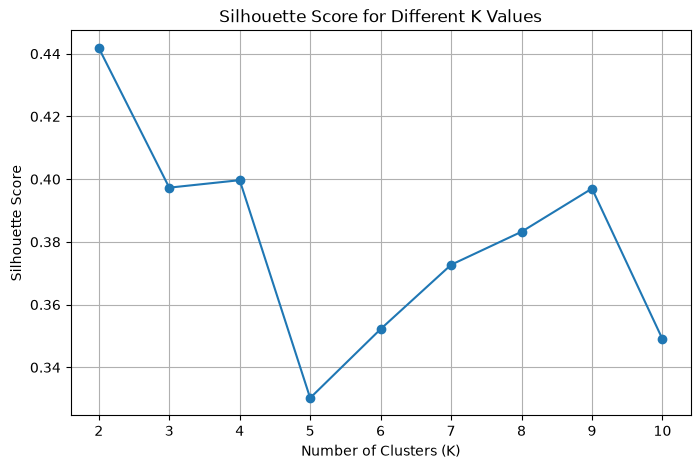

In [11]:
plt.figure(figsize=(8, 5))

plt.plot(
    k_values,
    silhouette_scores,
    marker="o"
)

plt.xlabel("Number of Clusters (K)")
plt.ylabel("Silhouette Score")
plt.title("Silhouette Score for Different K Values")

plt.xticks(list(k_values))
plt.grid(True)

plt.show()

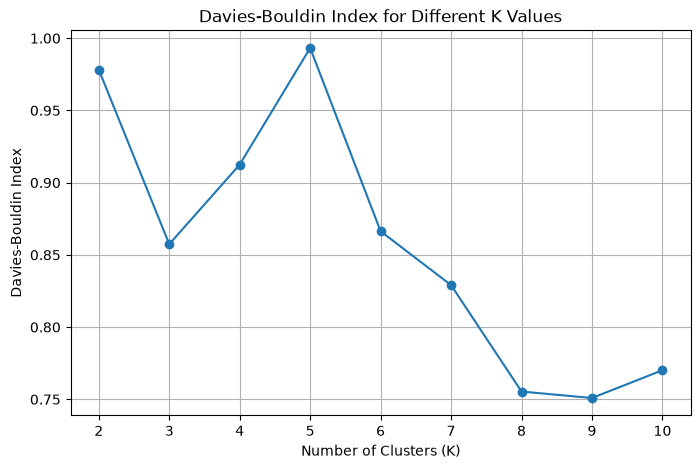

In [12]:
plt.figure(figsize=(8, 5))

plt.plot(
    k_values,
    davies_bouldin_scores,
    marker="o"
)

plt.xlabel("Number of Clusters (K)")
plt.ylabel("Davies-Bouldin Index")
plt.title("Davies-Bouldin Index for Different K Values")

plt.xticks(list(k_values))
plt.grid(True)

plt.show()

In [13]:
# Check cluster sizes for different K values

for k in [2, 3, 4, 8, 9]:
    
    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )
    
    labels = kmeans.fit_predict(x_scaled)
    
    cluster_sizes = pd.Series(labels).value_counts().sort_index()
    
    print(f"\nK = {k}")
    print(cluster_sizes)


K = 2
0    125
1    305
Name: count, dtype: int64

K = 3
0     67
1    189
2    174
Name: count, dtype: int64

K = 4
0    168
1     18
2    184
3     60
Name: count, dtype: int64

K = 8
0     47
1      5
2     80
3    116
4    110
5     14
6     49
7      9
Name: count, dtype: int64

K = 9
0     14
1    113
2     57
3     28
4     50
5     39
6      9
7      5
8    115
Name: count, dtype: int64


In [14]:
candidate_k = [2, 3, 4, 8, 9]

cluster_profiles = {}

for k in candidate_k:
    
    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )
    
    labels = kmeans.fit_predict(x_scaled)
    
    profile = x.copy()
    profile["Cluster"] = labels
    
    cluster_summary = (
        profile
        .groupby("Cluster")
        .agg(
            Count=("AOD_mean", "size"),
            AOD_mean=("AOD_mean", "mean"),
            LST_mean=("LST_mean", "mean")
        )
        .reset_index()
    )
    
    cluster_profiles[k] = cluster_summary
    
    print(f"\n{'='*50}")
    print(f"K = {k}")
    print(f"{'='*50}")
    print(cluster_summary)


K = 2
   Cluster  Count  AOD_mean    LST_mean
0        0    125  0.972328  320.539355
1        1    305  0.367533  311.188388

K = 3
   Cluster  Count  AOD_mean    LST_mean
0        0     67  1.302862  320.220148
1        1    189  0.368647  307.922348
2        2    174  0.440648  317.975885

K = 4
   Cluster  Count  AOD_mean    LST_mean
0        0    168  0.416216  317.684544
1        1     18  1.798205  313.312127
2        2    184  0.364570  307.842924
3        3     60  1.071098  322.102630

K = 8
   Cluster  Count  AOD_mean    LST_mean
0        0     47  0.742936  309.643451
1        1      5  2.308221  324.215360
2        2     80  0.454226  320.809443
3        3    116  0.259713  307.911262
4        4    110  0.372574  314.508617
5        5     14  1.575212  309.471494
6        6     49  1.105037  323.309176
7        7      9  0.392414  294.710924

K = 9
   Cluster  Count  AOD_mean    LST_mean
0        0     14  1.575212  309.471494
1        1    113  0.396269  314.476099
2    

In [15]:
# =====================================================
# K = 3 FINAL CANDIDATE - FIT K-MEANS
# =====================================================

kmeans_3 = KMeans(
    n_clusters=3,
    random_state=42,
    n_init=10
)

labels_3 = kmeans_3.fit_predict(x_scaled)

final_0530["Cluster_K3"] = labels_3

print(final_0530["Cluster_K3"].value_counts().sort_index())

Cluster_K3
0     67
1    189
2    174
Name: count, dtype: int64


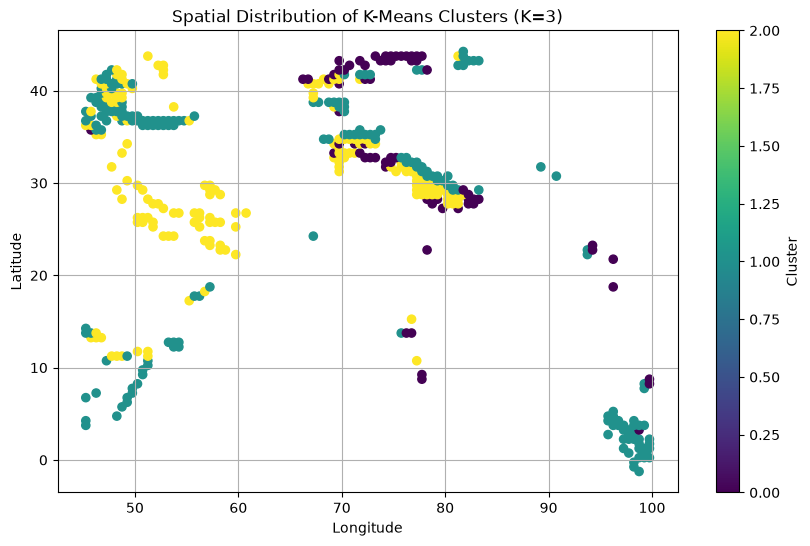

In [16]:
# =====================================================
# SPATIAL DISTRIBUTION OF K = 3 CLUSTERS
# =====================================================

plt.figure(figsize=(10, 6))

scatter = plt.scatter(
    final_0530["longitude"],
    final_0530["latitude"],
    c=final_0530["Cluster_K3"],
    cmap="viridis",
    s=35
)

plt.xlabel("Longitude")
plt.ylabel("Latitude")
plt.title("Spatial Distribution of K-Means Clusters (K=3)")

plt.colorbar(
    scatter,
    label="Cluster"
)

plt.grid(True)

plt.show()

In [17]:
from sklearn.decomposition import PCA

# Apply PCA to the standardized features
pca = PCA(n_components=2)

x_pca = pca.fit_transform(x_scaled)

print("Explained variance ratio:")
print(pca.explained_variance_ratio_)

print("\nExplained variance percentage:")
print(pca.explained_variance_ratio_ * 100)

print("\nTotal explained variance:")
print(pca.explained_variance_ratio_.sum() * 100, "%")

Explained variance ratio:
[0.6645229 0.3354771]

Explained variance percentage:
[66.45228975 33.54771025]

Total explained variance:
99.99999999999999 %


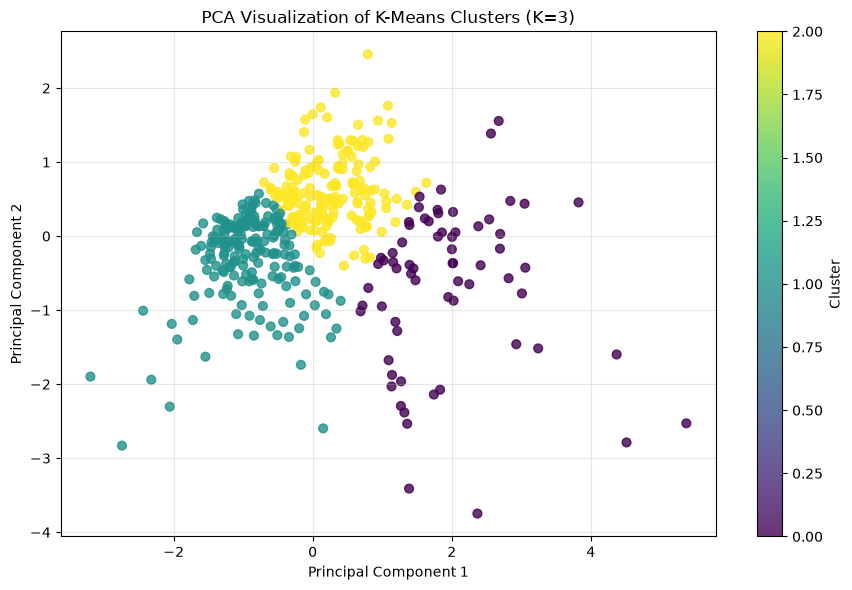

In [18]:
import matplotlib.pyplot as plt

plt.figure(figsize=(9, 6))

scatter = plt.scatter(
    x_pca[:, 0],
    x_pca[:, 1],
    c=labels_3,
    cmap="viridis",
    s=40,
    alpha=0.8
)

plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.title("PCA Visualization of K-Means Clusters (K=3)")

plt.colorbar(scatter, label="Cluster")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

In [19]:
# =====================================================
# CLUSTER PROFILING USING ALL ENVIRONMENTAL FEATURES
# =====================================================

profile_columns = [
    "AOD_mean",
    "LST_mean",
    "Rainfall_mean",
    "Rainfall_positive_pct",
    "Smoke_count",
    "Fire_count"
]

cluster_profile = (
    final_0530
    .groupby("Cluster_K3")[profile_columns]
    .agg(["mean", "median", "std"])
    .round(4)
)

print(cluster_profile)

           AOD_mean                  LST_mean                   Rainfall_mean  \
               mean  median     std      mean    median     std          mean   
Cluster_K3                                                                      
0            1.3029  1.2165  0.4195  320.2201  321.6117  6.8261        0.0001   
1            0.3686  0.3163  0.2205  307.9223  308.6230  4.0635        0.0000   
2            0.4406  0.4294  0.1838  317.9759  317.6173  3.4697        0.0000   

                          Rainfall_positive_pct                Smoke_count  \
           median     std                  mean median     std        mean   
Cluster_K3                                                                   
0             0.0  0.0006                0.1668    0.0  1.3650      0.0000   
1             0.0  0.0000                0.0044    0.0  0.0601      0.0476   
2             0.0  0.0000                0.0000    0.0  0.0000      0.0057   

                          Fire_count        

In [20]:
# =====================================================
# NONZERO ENVIRONMENTAL OBSERVATIONS BY CLUSTER
# =====================================================

event_columns = [
    "Rainfall_mean",
    "Rainfall_positive_pct",
    "Smoke_count",
    "Fire_count"
]

for column in event_columns:

    print(f"\n{'=' * 55}")
    print(f"Feature: {column}")
    print(f"{'=' * 55}")

    event_summary = (
        final_0530
        .groupby("Cluster_K3")[column]
        .agg(
            Total_Cells="count",
            Cells_With_Nonzero=lambda s: (s > 0).sum(),
            Mean_Value="mean"
        )
    )

    event_summary["Nonzero_Percentage"] = (
        event_summary["Cells_With_Nonzero"]
        / event_summary["Total_Cells"]
    ) * 100

    print(event_summary.round(4))


Feature: Rainfall_mean
            Total_Cells  Cells_With_Nonzero  Mean_Value  Nonzero_Percentage
Cluster_K3                                                                 
0                    67                   1      0.0001              1.4925
1                   189                   1      0.0000              0.5291
2                   174                   0      0.0000              0.0000

Feature: Rainfall_positive_pct
            Total_Cells  Cells_With_Nonzero  Mean_Value  Nonzero_Percentage
Cluster_K3                                                                 
0                    67                   1      0.1668              1.4925
1                   189                   1      0.0044              0.5291
2                   174                   0      0.0000              0.0000

Feature: Smoke_count
            Total_Cells  Cells_With_Nonzero  Mean_Value  Nonzero_Percentage
Cluster_K3                                                                 
0         

In [21]:
# =====================================================
# K-MEANS STABILITY ANALYSIS FOR K = 3
# =====================================================

from sklearn.cluster import KMeans
from sklearn.metrics import adjusted_rand_score

reference_model = KMeans(
    n_clusters=3,
    random_state=42,
    n_init=10
)

reference_labels = reference_model.fit_predict(x_scaled)

seeds = [0, 10, 20, 30, 40, 50, 60, 70, 80, 90]

ari_scores = []

for seed in seeds:

    model = KMeans(
        n_clusters=3,
        random_state=seed,
        n_init=10
    )

    labels = model.fit_predict(x_scaled)

    ari = adjusted_rand_score(
        reference_labels,
        labels
    )

    ari_scores.append(ari)

    print(f"Seed {seed}: ARI = {ari:.6f}")

print("\nMean ARI:", round(np.mean(ari_scores), 6))
print("Minimum ARI:", round(np.min(ari_scores), 6))
print("Maximum ARI:", round(np.max(ari_scores), 6))

Seed 0: ARI = 1.000000
Seed 10: ARI = 1.000000
Seed 20: ARI = 1.000000
Seed 30: ARI = 1.000000
Seed 40: ARI = 0.969666
Seed 50: ARI = 0.961487
Seed 60: ARI = 0.969666
Seed 70: ARI = 0.969666
Seed 80: ARI = 0.961487
Seed 90: ARI = 0.961487

Mean ARI: 0.979346
Minimum ARI: 0.961487
Maximum ARI: 1.0


In [22]:
# =====================================================
# SAVE K=3 CLUSTERING RESULTS
# =====================================================

# Fit the selected working configuration
final_kmeans = KMeans(
    n_clusters=3,
    random_state=42,
    n_init=10
)

final_0530["Cluster_K3"] = final_kmeans.fit_predict(x_scaled)

# Save observations with cluster assignments
final_0530.to_csv(
    DATA_DIR / "clustered_regional_dataset_0530.csv",
    index=False
)

# Create environmental profiles
profile_columns = [
    "AOD_mean",
    "LST_mean",
    "Rainfall_mean",
    "Rainfall_positive_pct",
    "Smoke_count",
    "Fire_count"
]

final_cluster_profiles = (
    final_0530
    .groupby("Cluster_K3")[profile_columns]
    .agg(["count", "mean", "median", "std"])
)

final_cluster_profiles.to_csv(
    DATA_DIR / "cluster_profiles_0530.csv"
)

print("Clustered dataset saved.")
print("Cluster profiles saved.")

print("\nCluster sizes:")
print(final_0530["Cluster_K3"].value_counts().sort_index())

Clustered dataset saved.
Cluster profiles saved.

Cluster sizes:
Cluster_K3
0     67
1    189
2    174
Name: count, dtype: int64


In [23]:
# =====================================================
# FINAL K=3 CLUSTER SUMMARY
# =====================================================

cluster_summary = (
    final_0530
    .groupby("Cluster_K3")
    .agg(
        Cell_Count=("AOD_mean", "size"),
        AOD_Mean=("AOD_mean", "mean"),
        AOD_Median=("AOD_mean", "median"),
        LST_Mean_K=("LST_mean", "mean"),
        LST_Median_K=("LST_mean", "median"),
        Rainfall_Active_Cells=(
            "Rainfall_mean",
            lambda s: (s > 0).sum()
        ),
        Smoke_Detection_Cells=(
            "Smoke_count",
            lambda s: (s > 0).sum()
        ),
        Fire_Detection_Cells=(
            "Fire_count",
            lambda s: (s > 0).sum()
        )
    )
    .round(4)
)

print(cluster_summary)

            Cell_Count  AOD_Mean  AOD_Median  LST_Mean_K  LST_Median_K  \
Cluster_K3                                                               
0                   67    1.3029      1.2165    320.2201      321.6117   
1                  189    0.3686      0.3163    307.9223      308.6230   
2                  174    0.4406      0.4294    317.9759      317.6173   

            Rainfall_Active_Cells  Smoke_Detection_Cells  Fire_Detection_Cells  
Cluster_K3                                                                      
0                               1                      0                     0  
1                               1                      4                     0  
2                               0                      1                     1  


In [24]:
from pathlib import Path

project_folder = PROJECT_DIR

# Count files by extension
extension_counts = {}

for file in project_folder.iterdir():
    if file.is_file():
        extension = file.suffix.lower() or "[no extension]"
        extension_counts[extension] = extension_counts.get(extension, 0) + 1

print("File counts by extension:\n")

for extension, count in sorted(extension_counts.items()):
    print(f"{extension}: {count}")

# Find original LST files anywhere inside the project folder
print("\nFiles with LST in their names:")

for file in project_folder.rglob("*"):
    if file.is_file() and "LST" in file.name.upper():
        print(file.name)

File counts by extension:

.csv: 1
.md: 1
.py: 1
.txt: 1
[no extension]: 1

Files with LST in their names:
AOD_vs_LST_clusters_0530.png
inspect_LST.py
regional_AOD_LST_0530.csv
regional_AOD_LST_0600.csv


In [25]:


for filename in [
    "regional_AOD_LST_0530.csv",
    "regional_AOD_LST_0600.csv"
]:
    file_path = DATA_DIR / filename

    df = pd.read_csv(file_path)

    print(f"\n{'=' * 50}")
    print("File:", filename)
    print("Shape:", df.shape)
    print("Columns:", df.columns.tolist())

    print("\nLST summary:")
    print(df[["LST_mean", "LST_median", "LST_std", "LST_count"]].describe())

    print("\nMissing LST values:")
    print(df[["LST_mean", "LST_median", "LST_std", "LST_count"]].isna().sum())


File: regional_AOD_LST_0530.csv
Shape: (430, 11)
Columns: ['latitude', 'longitude', 'time', 'AOD_mean', 'AOD_median', 'AOD_std', 'AOD_count', 'LST_mean', 'LST_median', 'LST_std', 'LST_count']

LST summary:
         LST_mean  LST_median     LST_std   LST_count
count  430.000000  430.000000  430.000000  430.000000
mean   313.906692  314.061791    3.750371   58.544186
std      6.926630    7.103277    1.709932   34.348843
min    286.645050  283.775630    0.740641   10.000000
25%    308.946507  309.018450    2.529718   30.000000
50%    313.895005  313.693390    3.445148   56.000000
75%    318.756012  318.889678    4.614348   78.750000
max    334.838600  335.082340   10.825321  175.000000

Missing LST values:
LST_mean      0
LST_median    0
LST_std       0
LST_count     0
dtype: int64

File: regional_AOD_LST_0600.csv
Shape: (389, 11)
Columns: ['latitude', 'longitude', 'time', 'AOD_mean', 'AOD_median', 'AOD_std', 'AOD_count', 'LST_mean', 'LST_median', 'LST_std', 'LST_count']

LST summary:
  

In [26]:
import pandas as pd
from pathlib import Path

project_folder = PROJECT_DIR

df_0530 = pd.read_csv(DATA_DIR / "regional_AOD_LST_0530.csv")
df_0600 = pd.read_csv(DATA_DIR / "regional_AOD_LST_0600.csv")

# Match locations that appear in both observations
matched = df_0530.merge(
    df_0600,
    on=["latitude", "longitude"],
    how="inner",
    suffixes=("_0530", "_0600")
)

print("Grid cells at 05:30:", len(df_0530))
print("Grid cells at 06:00:", len(df_0600))
print("Matching grid cells:", len(matched))
print("Unique matched locations:",
      matched[["latitude", "longitude"]].drop_duplicates().shape[0])

Grid cells at 05:30: 430
Grid cells at 06:00: 389
Matching grid cells: 352
Unique matched locations: 352


In [27]:
# Calculate changes at matching geographic locations
matched["AOD_change"] = (
    matched["AOD_mean_0600"] - matched["AOD_mean_0530"]
)

matched["LST_change"] = (
    matched["LST_mean_0600"] - matched["LST_mean_0530"]
)

print("Matched locations:", len(matched))

print("\nAOD change (06:00 minus 05:30):")
print(matched["AOD_change"].describe())

print("\nLST change in Kelvin (06:00 minus 05:30):")
print(matched["LST_change"].describe())

print("\nLocations with increasing AOD:",
      (matched["AOD_change"] > 0).sum())

print("Locations with decreasing AOD:",
      (matched["AOD_change"] < 0).sum())

print("Locations with increasing LST:",
      (matched["LST_change"] > 0).sum())

print("Locations with decreasing LST:",
      (matched["LST_change"] < 0).sum())


Matched locations: 352

AOD change (06:00 minus 05:30):
count    352.000000
mean       0.038848
std        0.117018
min       -0.504298
25%       -0.009643
50%        0.024771
75%        0.081404
max        0.501228
Name: AOD_change, dtype: float64

LST change in Kelvin (06:00 minus 05:30):
count    352.000000
mean       2.001108
std        1.641935
min       -8.424070
25%        0.920680
50%        2.065045
75%        3.099090
max        8.394840
Name: LST_change, dtype: float64

Locations with increasing AOD: 232
Locations with decreasing AOD: 120
Locations with increasing LST: 322
Locations with decreasing LST: 30


In [28]:
# Locations with the 10 largest AOD increases
largest_increases = matched.nlargest(10, "AOD_change")[
    ["latitude", "longitude",
     "AOD_mean_0530", "AOD_mean_0600",
     "AOD_change", "LST_change"]
]

print("10 locations with the largest AOD increases:")
print(largest_increases.to_string(index=False))

# Locations with the 10 largest AOD decreases
largest_decreases = matched.nsmallest(10, "AOD_change")[
    ["latitude", "longitude",
     "AOD_mean_0530", "AOD_mean_0600",
     "AOD_change", "LST_change"]
]

print("\n10 locations with the largest AOD decreases:")
print(largest_decreases.to_string(index=False))

10 locations with the largest AOD increases:
 latitude  longitude  AOD_mean_0530  AOD_mean_0600  AOD_change  LST_change
    29.25      57.25       0.325195       0.826423    0.501228     4.02142
     3.25      97.75       0.256252       0.673307    0.417055    -0.83377
    43.75      76.75       1.216521       1.605957    0.389436     2.13710
    43.75      75.25       1.376550       1.763386    0.386836     2.26770
    29.75      79.75       0.497237       0.859513    0.362276     0.99513
     2.25      98.75       0.529750       0.880378    0.350628    -1.18700
    34.25      71.75       0.603415       0.953503    0.350087     3.63356
    28.75      57.25       0.348532       0.694659    0.346128     2.66916
    41.75      69.75       0.793415       1.126185    0.332770     2.56604
    39.75      46.75       0.312521       0.613857    0.301336     4.20080

10 locations with the largest AOD decreases:
 latitude  longitude  AOD_mean_0530  AOD_mean_0600  AOD_change  LST_change
    21.75

In [29]:
print("Latitude range:")
print("Minimum:", matched["latitude"].min())
print("Maximum:", matched["latitude"].max())

print("\nLongitude range:")
print("Minimum:", matched["longitude"].min())
print("Maximum:", matched["longitude"].max())

print("\nNumber of unique latitudes:",
      matched["latitude"].nunique())

print("Number of unique longitudes:",
      matched["longitude"].nunique())

print("\nSample geographic coordinates:")
print(
    matched[["latitude", "longitude"]]
    .drop_duplicates()
    .sample(min(10, len(matched)), random_state=42)
    .sort_values(["latitude", "longitude"])
    .to_string(index=False)
)

Latitude range:
Minimum: -1.25
Maximum: 44.25

Longitude range:
Minimum: 45.25
Maximum: 99.75

Number of unique latitudes: 77
Number of unique longitudes: 76

Sample geographic coordinates:
 latitude  longitude
     6.75      45.25
    11.25      51.25
    13.25      45.75
    22.75      58.75
    27.75      82.25
    28.25      80.25
    28.75      80.75
    30.25      49.25
    35.75      46.25
    36.25      53.25


In [30]:
# Approximate geographic filter for India
india_approx = matched[
    matched["latitude"].between(6, 38)
    & matched["longitude"].between(68, 98)
].copy()

print("All matching locations:", len(matched))
print("Locations within approximate India bounds:", len(india_approx))

print("\nLatitude range:")
print(india_approx["latitude"].min(), "to",
      india_approx["latitude"].max())

print("\nLongitude range:")
print(india_approx["longitude"].min(), "to",
      india_approx["longitude"].max())

print("\nFirst 10 locations:")
print(
    india_approx[["latitude", "longitude"]]
    .drop_duplicates()
    .head(10)
    .to_string(index=False)
)

All matching locations: 352
Locations within approximate India bounds: 110

Latitude range:
21.75 to 37.75

Longitude range:
68.25 to 96.25

First 10 locations:
 latitude  longitude
    21.75      96.25
    22.25      93.75
    22.75      94.25
    27.75      80.25
    27.75      80.75
    27.75      81.25
    27.75      82.25
    27.75      82.75
    28.25      78.25
    28.25      79.25


In [31]:
%pip install geopandas

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.1.2 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [32]:
import geopandas as gpd

url = "https://naturalearth.s3.amazonaws.com/110m_cultural/ne_110m_admin_0_countries.zip"

world = gpd.read_file(url)

india_boundary = world[world["ADMIN"] == "India"].copy()

print("Countries loaded:", len(world))
print("India boundary found:", len(india_boundary) == 1)

Countries loaded: 177
India boundary found: True


In [33]:
import geopandas as gpd

# Convert the matched locations into geographic points
points = gpd.GeoDataFrame(
    matched.copy(),
    geometry=gpd.points_from_xy(
        matched["longitude"],
        matched["latitude"]
    ),
    crs="EPSG:4326"
)

# Ensure the India boundary uses the same coordinate system
india_boundary = india_boundary.to_crs("EPSG:4326")

# Keep only points inside India's boundary
india_points = gpd.sjoin(
    points,
    india_boundary[["geometry"]],
    how="inner",
    predicate="within"
)

# Remove the temporary spatial columns
india_matched = india_points.drop(
    columns=["geometry", "index_right"],
    errors="ignore"
).copy()

print("Original matching locations:", len(matched))
print("Locations inside India:", len(india_matched))
print("Unique Indian coordinates:",
      india_matched[["latitude", "longitude"]]
      .drop_duplicates().shape[0])

print("\nLatitude range:")
print(india_matched["latitude"].min(),
      "to", india_matched["latitude"].max())

print("\nLongitude range:")
print(india_matched["longitude"].min(),
      "to", india_matched["longitude"].max())

Original matching locations: 352
Locations inside India: 54
Unique Indian coordinates: 54

Latitude range:
27.75 to 32.75

Longitude range:
74.75 to 82.25


In [34]:
# Geographic coverage before filtering
print("Original 05:30 dataset:", len(df_0530))
print("Original matching dataset:", len(matched))
print("India-only matching dataset:", len(india_matched))

print("\nOriginal 05:30 coordinate ranges:")
print(
    "Latitude:",
    df_0530["latitude"].min(),
    "to",
    df_0530["latitude"].max()
)
print(
    "Longitude:",
    df_0530["longitude"].min(),
    "to",
    df_0530["longitude"].max()
)

print("\nIndia-only grid-cell coordinates:")
print(
    india_matched[["latitude", "longitude"]]
    .sort_values(["latitude", "longitude"])
    .to_string(index=False)
)

Original 05:30 dataset: 430
Original matching dataset: 352
India-only matching dataset: 54

Original 05:30 coordinate ranges:
Latitude: -1.25 to 44.25
Longitude: 45.25 to 99.75

India-only grid-cell coordinates:
 latitude  longitude
    27.75      80.25
    27.75      80.75
    27.75      81.25
    27.75      82.25
    28.25      78.25
    28.25      79.25
    28.25      80.25
    28.25      80.75
    28.25      81.25
    28.75      77.75
    28.75      78.25
    28.75      78.75
    28.75      79.25
    29.25      77.25
    29.25      77.75
    29.25      78.25
    29.25      78.75
    29.25      79.25
    29.25      79.75
    29.25      80.25
    29.75      77.25
    29.75      77.75
    29.75      78.25
    29.75      78.75
    29.75      79.25
    29.75      79.75
    29.75      80.25
    30.25      78.25
    30.25      78.75
    30.25      79.25
    30.25      79.75
    30.75      77.25
    30.75      77.75
    30.75      78.25
    30.75      78.75
    30.75      79.25
    31.25  

In [35]:

# Convert every 05:30 grid-cell centre into a geographic point
points_0530 = gpd.GeoDataFrame(
    df_0530.copy(),
    geometry=gpd.points_from_xy(
        df_0530["longitude"],
        df_0530["latitude"]
    ),
    crs="EPSG:4326"
)

# Keep points inside India's boundary
india_points_0530 = gpd.sjoin(
    points_0530,
    india_boundary[["geometry"]],
    how="inner",
    predicate="within"
)

# Create a separate India-only dataset
india_0530 = india_points_0530.drop(
    columns=["geometry", "index_right"],
    errors="ignore"
).copy()

print("All 05:30 locations:", len(df_0530))
print("Locations inside India:", len(india_0530))
print(
    "Unique Indian coordinates:",
    india_0530[["latitude", "longitude"]]
    .drop_duplicates()
    .shape[0]
)

print("\nIndian coordinate ranges:")
print(
    "Latitude:",
    india_0530["latitude"].min(),
    "to",
    india_0530["latitude"].max()
)
print(
    "Longitude:",
    india_0530["longitude"].min(),
    "to",
    india_0530["longitude"].max()
)

All 05:30 locations: 430
Locations inside India: 70
Unique Indian coordinates: 70

Indian coordinate ranges:
Latitude: 8.75 to 32.75
Longitude: 74.75 to 82.25


In [36]:
print("Latitude range:", df_0530["latitude"].min(), "to", df_0530["latitude"].max())
print("Longitude range:", df_0530["longitude"].min(), "to", df_0530["longitude"].max())

print("\nNumber of unique latitudes:", df_0530["latitude"].nunique())
print("Number of unique longitudes:", df_0530["longitude"].nunique())

print("\nFirst 10 coordinates:")
print(df_0530[["latitude", "longitude"]].head(10))

Latitude range: -1.25 to 44.25
Longitude range: 45.25 to 99.75

Number of unique latitudes: 82
Number of unique longitudes: 78

First 10 coordinates:
   latitude  longitude
0     -1.25      98.75
1     -0.75      98.25
2     -0.25      98.25
3      0.25      98.75
4      0.25      99.25
5      0.25      99.75
6      0.75      97.75
7      0.75      99.25
8      1.25      97.25
9      1.25      98.75


In [37]:
# Count cells by latitude band
print("Cells by latitude band:")

print(
    pd.cut(
        df_0530["latitude"],
        bins=[-10, 0, 10, 20, 30, 40, 50]
    ).value_counts().sort_index()
)

# Count cells by longitude band
print("\nCells by longitude band:")

print(
    pd.cut(
        df_0530["longitude"],
        bins=[40, 50, 60, 70, 80, 90, 100, 110]
    ).value_counts().sort_index()
)

Cells by latitude band:
latitude
(-10, 0]      3
(0, 10]      55
(10, 20]     33
(20, 30]     97
(30, 40]    164
(40, 50]     78
Name: count, dtype: int64

Cells by longitude band:
longitude
(40, 50]       96
(50, 60]       86
(60, 70]       40
(70, 80]      123
(80, 90]       35
(90, 100]      50
(100, 110]      0
Name: count, dtype: int64


In [38]:
aggregation_file = NOTEBOOKS_DIR / "aggrigation.ipynb"

print("File exists:", aggregation_file.exists())

File exists: False


In [39]:
if aggregation_file.exists():
    print("File size:", aggregation_file.stat().st_size, "bytes")

    with open(aggregation_file, "r", encoding="utf-8") as f:
        print(repr(f.read(500)))
else:
    print("Aggregation notebook not found. Skipping this check.")

Aggregation notebook not found. Skipping this check.


In [40]:
aod_notebook_file = project_folder / "01_AOD_Data_Preparation.ipynb"
aod_notebook_file = NOTEBOOKS_DIR / "01_AOD_Data_Preparation.ipynb"
print("File exists:", aod_notebook_file.exists())
print(
    "File size:",
    aod_notebook_file.stat().st_size if aod_notebook_file.exists() else "Not found",
    "bytes"



)
print("File exists:", aod_notebook_file.exists())
print("File size:", aod_notebook_file.stat().st_size, "bytes")

File exists: True
File size: 38234 bytes
File exists: True
File size: 38234 bytes


In [41]:
print("05:30 dataset shape:", df_0530.shape)

print("\nSample of Indian locations:")
print(
    india_0530[
        ["latitude", "longitude", "AOD_mean", "LST_mean"]
    ].sort_values("latitude").head(15)
)

print("\nNumber of cells per latitude band in India:")
print(
    pd.cut(
        india_0530["latitude"],
        bins=[0, 10, 20, 30, 40]
    ).value_counts().sort_index()
)

05:30 dataset shape: (430, 11)

Sample of Indian locations:
     latitude  longitude  AOD_mean   LST_mean
53       8.75      77.75  1.329667  321.15308
56       9.25      77.75  1.177761  322.82767
61      10.75      77.25  0.815538  319.04990
80      13.75      75.75  1.006465  309.47153
81      13.75      76.25  1.025051  312.81863
82      13.75      76.75  0.944359  318.42026
84      15.25      76.75  0.277805  318.72836
96      22.75      78.25  1.237017  322.00415
130     27.25      79.75  1.820400  321.08377
131     27.25      81.25  1.529095  324.90753
134     27.75      78.75  1.350593  319.41867
135     27.75      80.25  0.668701  319.60245
136     27.75      80.75  0.567940  320.30475
137     27.75      81.25  0.714791  321.39440
138     27.75      82.25  0.943699  322.96664

Number of cells per latitude band in India:
latitude
(0, 10]      2
(10, 20]     5
(20, 30]    32
(30, 40]    31
Name: count, dtype: int64


In [42]:
files_to_check = [
    "regional_AOD_LST_0530.csv",
    "regional_AOD_LST_0600.csv",
    "final_regional_dataset_0530.csv",
    "clustered_regional_dataset_0530.csv",
    "cluster_profiles_0530.csv"
]

for filename in files_to_check:
    file_path = DATA_DIR / filename

    if file_path.exists():
        data = pd.read_csv(file_path)
        print(f"\n{filename}")
        print(f"  Rows: {data.shape[0]}")
        print(f"  Columns: {data.shape[1]}")
        print(f"  Column names: {data.columns.tolist()}")
    else:
        print(f"\n{filename}: NOT FOUND")


regional_AOD_LST_0530.csv
  Rows: 430
  Columns: 11
  Column names: ['latitude', 'longitude', 'time', 'AOD_mean', 'AOD_median', 'AOD_std', 'AOD_count', 'LST_mean', 'LST_median', 'LST_std', 'LST_count']

regional_AOD_LST_0600.csv
  Rows: 389
  Columns: 11
  Column names: ['latitude', 'longitude', 'time', 'AOD_mean', 'AOD_median', 'AOD_std', 'AOD_count', 'LST_mean', 'LST_median', 'LST_std', 'LST_count']

final_regional_dataset_0530.csv
  Rows: 430
  Columns: 19
  Column names: ['latitude', 'longitude', 'time', 'AOD_mean', 'AOD_median', 'AOD_std', 'AOD_count', 'LST_mean', 'LST_median', 'LST_std', 'LST_count', 'Rainfall_mean', 'Rainfall_median', 'Rainfall_max', 'Rainfall_std', 'Rainfall_count', 'Rainfall_positive_pct', 'Smoke_count', 'Fire_count']

clustered_regional_dataset_0530.csv
  Rows: 430
  Columns: 20
  Column names: ['latitude', 'longitude', 'time', 'AOD_mean', 'AOD_median', 'AOD_std', 'AOD_count', 'LST_mean', 'LST_median', 'LST_std', 'LST_count', 'Rainfall_mean', 'Rainfall_media

In [43]:
clustered = pd.read_csv(
    DATA_DIR / "clustered_regional_dataset_0530.csv"
)
print("Dataset shape:", clustered.shape)

print("\nCluster label counts:")
print(clustered["Cluster_K3"].value_counts().sort_index())

print("\nMissing cluster labels:", clustered["Cluster_K3"].isna().sum())

print("\nUnique cluster labels:", sorted(clustered["Cluster_K3"].unique()))

Dataset shape: (430, 20)

Cluster label counts:
Cluster_K3
0     67
1    189
2    174
Name: count, dtype: int64

Missing cluster labels: 0

Unique cluster labels: [np.int64(0), np.int64(1), np.int64(2)]


In [44]:
profiles = pd.read_csv(DATA_DIR / "cluster_profiles_0530.csv")

print("Shape:", profiles.shape)
print("\nFirst 5 rows:")
print(profiles.to_string(index=False))


Shape: (5, 25)

First 5 rows:
Unnamed: 0 AOD_mean          AOD_mean.1 AOD_mean.2          AOD_mean.3 LST_mean         LST_mean.1         LST_mean.2         LST_mean.3 Rainfall_mean       Rainfall_mean.1 Rainfall_mean.2       Rainfall_mean.3 Rainfall_positive_pct Rainfall_positive_pct.1 Rainfall_positive_pct.2 Rainfall_positive_pct.3 Smoke_count        Smoke_count.1 Smoke_count.2       Smoke_count.3 Fire_count         Fire_count.1 Fire_count.2        Fire_count.3
       NaN    count                mean     median                 std    count               mean             median                std         count                  mean          median                   std                 count                    mean                  median                     std       count                 mean        median                 std      count                 mean       median                 std
Cluster_K3      NaN                 NaN        NaN                 NaN      NaN                N

In [45]:

# Load the verified clustered dataset
clustered = pd.read_csv(
    DATA_DIR / "clustered_regional_dataset_0530.csv"
)

# Select features for interpreting the clusters
profile_features = [
    "AOD_mean",
    "LST_mean",
    "Rainfall_mean",
    "Rainfall_positive_pct",
    "Smoke_count",
    "Fire_count"
]

# Calculate descriptive statistics for each cluster
cluster_profiles = clustered.groupby("Cluster_K3")[profile_features].agg(
    ["count", "mean", "median", "std"]
)

# Save the clean profile table
cluster_profiles.to_csv(
    DATA_DIR / "cluster_profiles_0530.csv",
    index=True
)

print("Cluster profile shape:", cluster_profiles.shape)
print("\nCluster profiles:")
display(cluster_profiles.round(3))



Cluster profile shape: (3, 24)

Cluster profiles:


AOD_mean                      LST_mean                           \
              count   mean median    std    count     mean   median    std   
Cluster_K3                                                                   
0                67  1.303  1.217  0.419       67  320.220  321.612  6.826   
1               189  0.369  0.316  0.220      189  307.922  308.623  4.064   
2               174  0.441  0.429  0.184      174  317.976  317.617  3.470   

           Rainfall_mean       ... Rainfall_positive_pct        Smoke_count  \
                   count mean  ...                median    std       count   
Cluster_K3                     ...                                            
0                     67  0.0  ...                   0.0  1.365          67   
1                    189  0.0  ...                   0.0  0.060         189   
2                    174  0.0  ...                   0.0  0.000         174   

                                Fire_count                       
             mean median    std      count   mean median    std  
Cluster_K3                                                       
0           0.000    0.0  0.000         67  0.000    0.0  0.000  
1           0.048    0.0  0.376        189  0.000    0.0  0.000  
2           0.006    0.0  0.076        174  0.011    0.0  0.152  

[3 rows x 24 columns]

In [46]:
notebook_file = NOTEBOOKS_DIR / "02_Clustering_Analysis.ipynb"

print("File exists:", notebook_file.exists())

if notebook_file.exists():
    print("File size:", notebook_file.stat().st_size, "bytes")
else:
    print("Notebook not found.")

File exists: True
File size: 1106050 bytes


In [48]:
import pandas as pd
import matplotlib.pyplot as plt

clustered = pd.read_csv(
    DATA_DIR / "clustered_regional_dataset_0530.csv"
)

print("Total cells:", len(clustered))
print("\nCluster distribution:")
print(clustered["Cluster_K3"].value_counts().sort_index())

Total cells: 430

Cluster distribution:
Cluster_K3
0     67
1    189
2    174
Name: count, dtype: int64


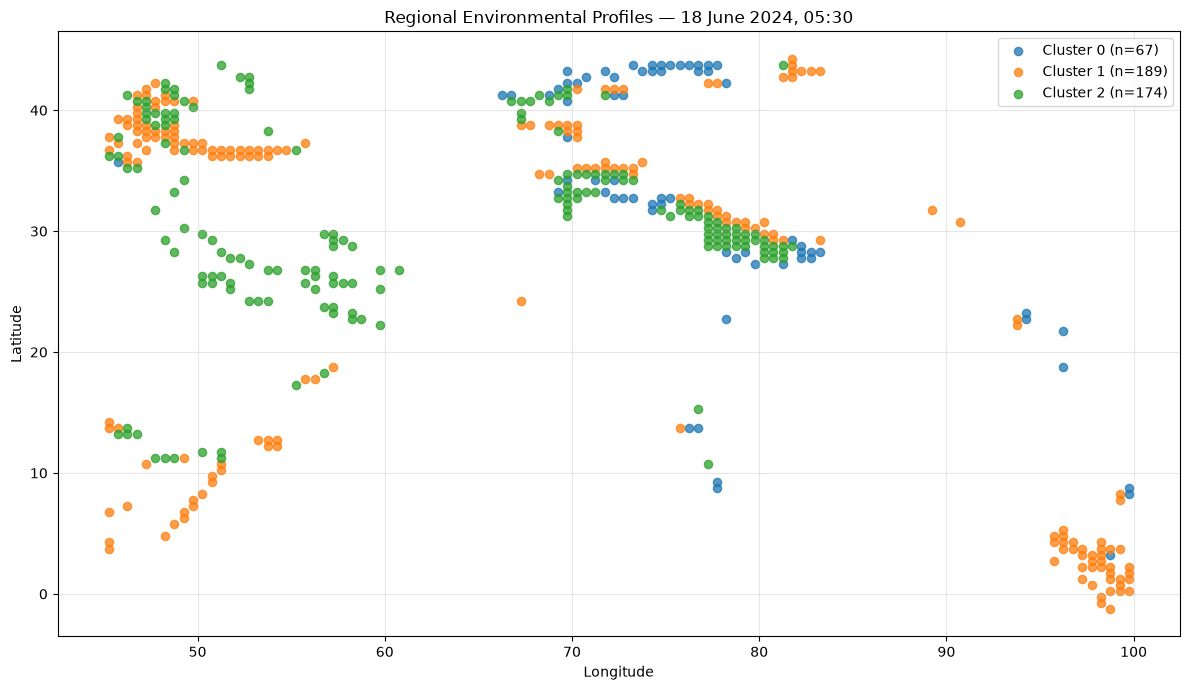

In [49]:
plt.figure(figsize=(12, 7))

for cluster in sorted(clustered["Cluster_K3"].unique()):
    subset = clustered[clustered["Cluster_K3"] == cluster]

    plt.scatter(
        subset["longitude"],
        subset["latitude"],
        label=f"Cluster {cluster} (n={len(subset)})",
        s=35,
        alpha=0.75
    )

plt.xlabel("Longitude")
plt.ylabel("Latitude")
plt.title("Regional Environmental Profiles — 18 June 2024, 05:30")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

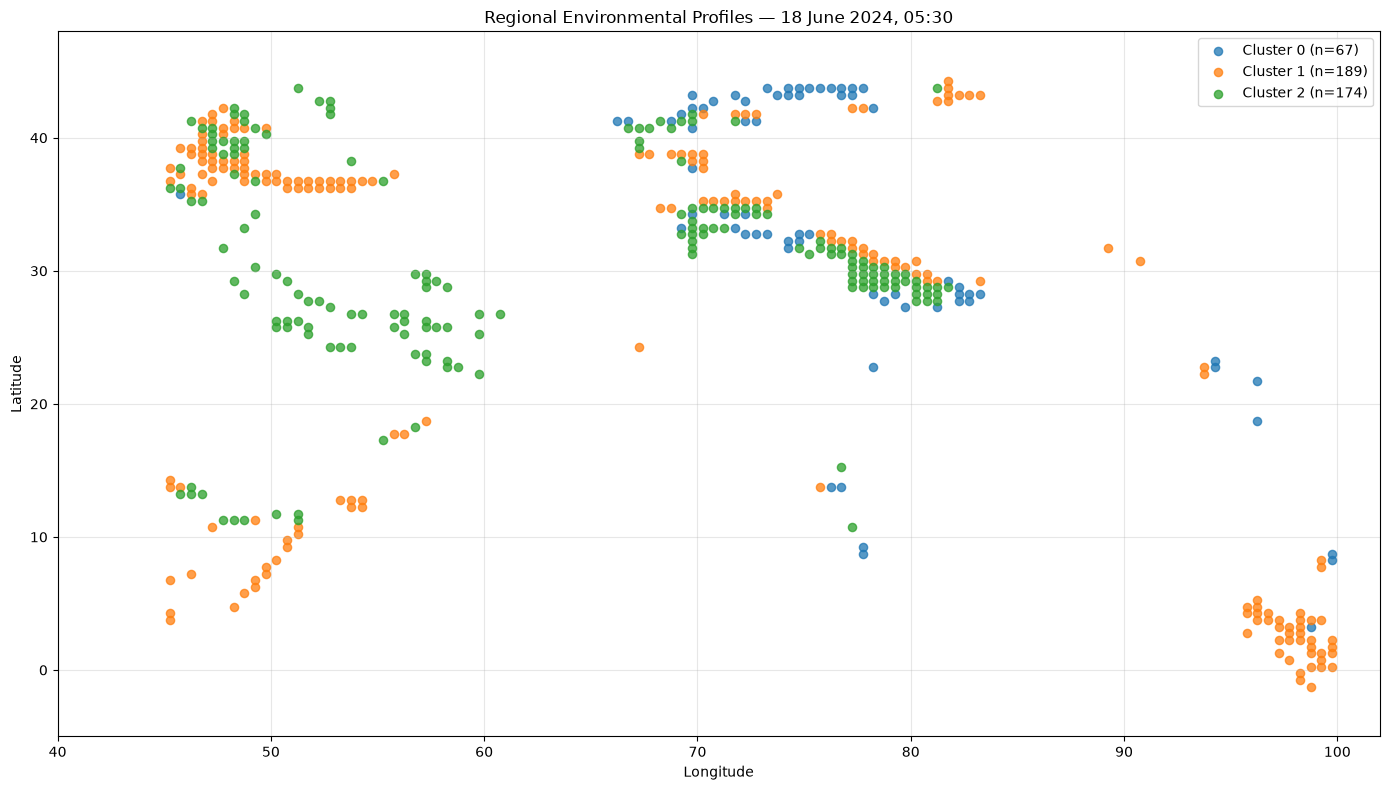

In [52]:

    # Load the saved clustering results
clustered = pd.read_csv(
    DATA_DIR / "clustered_regional_dataset_0530.csv"
)

fig, ax = plt.subplots(figsize=(14, 8))

# Plot each cluster
for cluster in sorted(clustered["Cluster_K3"].unique()):
    subset = clustered[clustered["Cluster_K3"] == cluster]

    ax.scatter(
        subset["longitude"],
        subset["latitude"],
        label=f"Cluster {cluster} (n={len(subset)})",
        s=35,
        alpha=0.75
    )

ax.set_xlim(40, 102)
ax.set_ylim(-5, 48)

ax.set_xlabel("Longitude")
ax.set_ylabel("Latitude")
ax.set_title(
    "Regional Environmental Profiles — "
    "18 June 2024, 05:30"
)

ax.legend()
ax.grid(True, alpha=0.3)
plt.tight_layout()

# Save the figure
plt.savefig(
    project_folder / "regional_cluster_map_0530.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

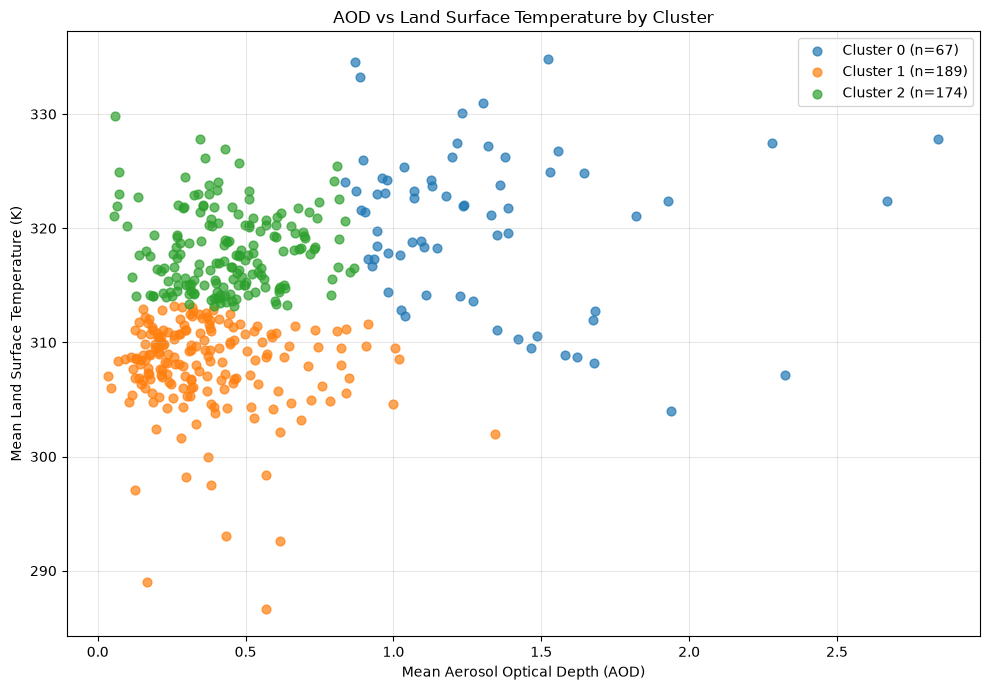

In [53]:
clustered = pd.read_csv(
    DATA_DIR / "clustered_regional_dataset_0530.csv"
)

plt.figure(figsize=(10, 7))

for cluster in sorted(clustered["Cluster_K3"].unique()):
    subset = clustered[clustered["Cluster_K3"] == cluster]

    plt.scatter(
        subset["AOD_mean"],
        subset["LST_mean"],
        label=f"Cluster {cluster} (n={len(subset)})",
        s=40,
        alpha=0.7
    )

plt.xlabel("Mean Aerosol Optical Depth (AOD)")
plt.ylabel("Mean Land Surface Temperature (K)")
plt.title("AOD vs Land Surface Temperature by Cluster")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()

plt.savefig(
    project_folder / "AOD_vs_LST_clusters_0530.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [54]:
from pathlib import Path

output_files = [
    "final_regional_dataset_0530.csv",
    "clustered_regional_dataset_0530.csv",
    "cluster_profiles_0530.csv",
    "regional_cluster_map_0530.png",
    "AOD_vs_LST_clusters_0530.png"
]

for filename in output_files:
    file_path = project_folder / filename

    if file_path.exists():
        print(f"FOUND: {filename} ({file_path.stat().st_size:,} bytes)")
    else:
        print(f"MISSING: {filename}")

MISSING: final_regional_dataset_0530.csv
MISSING: clustered_regional_dataset_0530.csv
FOUND: cluster_profiles_0530.csv (648 bytes)
FOUND: regional_cluster_map_0530.png (335,700 bytes)
FOUND: AOD_vs_LST_clusters_0530.png (444,068 bytes)


In [55]:
import geopandas as gpd
from pathlib import Path

project_folder = PROJECT_DIR

boundary_file = (
    project_folder / "map_boundaries" /
    "ne_110m_admin_0_countries.shp"
)

countries = gpd.read_file(boundary_file)

print("Countries loaded:", len(countries))
print(countries.columns.tolist())

Countries loaded: 177
['featurecla', 'scalerank', 'LABELRANK', 'SOVEREIGNT', 'SOV_A3', 'ADM0_DIF', 'LEVEL', 'TYPE', 'TLC', 'ADMIN', 'ADM0_A3', 'GEOU_DIF', 'GEOUNIT', 'GU_A3', 'SU_DIF', 'SUBUNIT', 'SU_A3', 'BRK_DIFF', 'NAME', 'NAME_LONG', 'BRK_A3', 'BRK_NAME', 'BRK_GROUP', 'ABBREV', 'POSTAL', 'FORMAL_EN', 'FORMAL_FR', 'NAME_CIAWF', 'NOTE_ADM0', 'NOTE_BRK', 'NAME_SORT', 'NAME_ALT', 'MAPCOLOR7', 'MAPCOLOR8', 'MAPCOLOR9', 'MAPCOLOR13', 'POP_EST', 'POP_RANK', 'POP_YEAR', 'GDP_MD', 'GDP_YEAR', 'ECONOMY', 'INCOME_GRP', 'FIPS_10', 'ISO_A2', 'ISO_A2_EH', 'ISO_A3', 'ISO_A3_EH', 'ISO_N3', 'ISO_N3_EH', 'UN_A3', 'WB_A2', 'WB_A3', 'WOE_ID', 'WOE_ID_EH', 'WOE_NOTE', 'ADM0_ISO', 'ADM0_DIFF', 'ADM0_TLC', 'ADM0_A3_US', 'ADM0_A3_FR', 'ADM0_A3_RU', 'ADM0_A3_ES', 'ADM0_A3_CN', 'ADM0_A3_TW', 'ADM0_A3_IN', 'ADM0_A3_NP', 'ADM0_A3_PK', 'ADM0_A3_DE', 'ADM0_A3_GB', 'ADM0_A3_BR', 'ADM0_A3_IL', 'ADM0_A3_PS', 'ADM0_A3_SA', 'ADM0_A3_EG', 'ADM0_A3_MA', 'ADM0_A3_PT', 'ADM0_A3_AR', 'ADM0_A3_JP', 'ADM0_A3_KO', 'ADM0_A3_

In [56]:
import pandas as pd
from pathlib import Path
file_path = DATA_DIR / "clustered_regional_dataset_0530.csv"

clustered_df = pd.read_csv(file_path)

print("Dataset shape:", clustered_df.shape)
print("\nColumn names:")
print(clustered_df.columns.tolist())

Dataset shape: (430, 20)

Column names:
['latitude', 'longitude', 'time', 'AOD_mean', 'AOD_median', 'AOD_std', 'AOD_count', 'LST_mean', 'LST_median', 'LST_std', 'LST_count', 'Rainfall_mean', 'Rainfall_median', 'Rainfall_max', 'Rainfall_std', 'Rainfall_count', 'Rainfall_positive_pct', 'Smoke_count', 'Fire_count', 'Cluster_K3']


In [57]:
print(clustered_df.columns.tolist())
print(clustered_df[["longitude", "latitude", "Cluster_K3"]].head())

['latitude', 'longitude', 'time', 'AOD_mean', 'AOD_median', 'AOD_std', 'AOD_count', 'LST_mean', 'LST_median', 'LST_std', 'LST_count', 'Rainfall_mean', 'Rainfall_median', 'Rainfall_max', 'Rainfall_std', 'Rainfall_count', 'Rainfall_positive_pct', 'Smoke_count', 'Fire_count', 'Cluster_K3']
   longitude  latitude  Cluster_K3
0      98.75     -1.25           1
1      98.25     -0.75           1
2      98.25     -0.25           1
3      98.75      0.25           1
4      99.25      0.25           1


In [58]:
%whos DataFrame

Variable                 Type         Data/Info
-----------------------------------------------
cluster_profile          DataFrame    Shape: (3, 18)
cluster_profiles         DataFrame    Shape: (3, 24)
cluster_summary          DataFrame    Shape: (3, 8)
clustered                DataFrame    Shape: (430, 20)
clustered_df             DataFrame    Shape: (430, 20)
data                     DataFrame    Shape: (5, 25)
df                       DataFrame    Shape: (389, 11)
df_0530                  DataFrame    Shape: (430, 11)
df_0600                  DataFrame    Shape: (389, 11)
event_summary            DataFrame    Shape: (3, 4)
final_0530               DataFrame    Shape: (430, 20)
final_cluster_profiles   DataFrame    Shape: (3, 24)
india_0530               DataFrame    Shape: (70, 11)
india_approx             DataFrame    Shape: (110, 22)
india_matched            DataFrame    Shape: (54, 22)
largest_decreases        DataFrame    Shape: (10, 6)
largest_increases        DataFrame    Shap

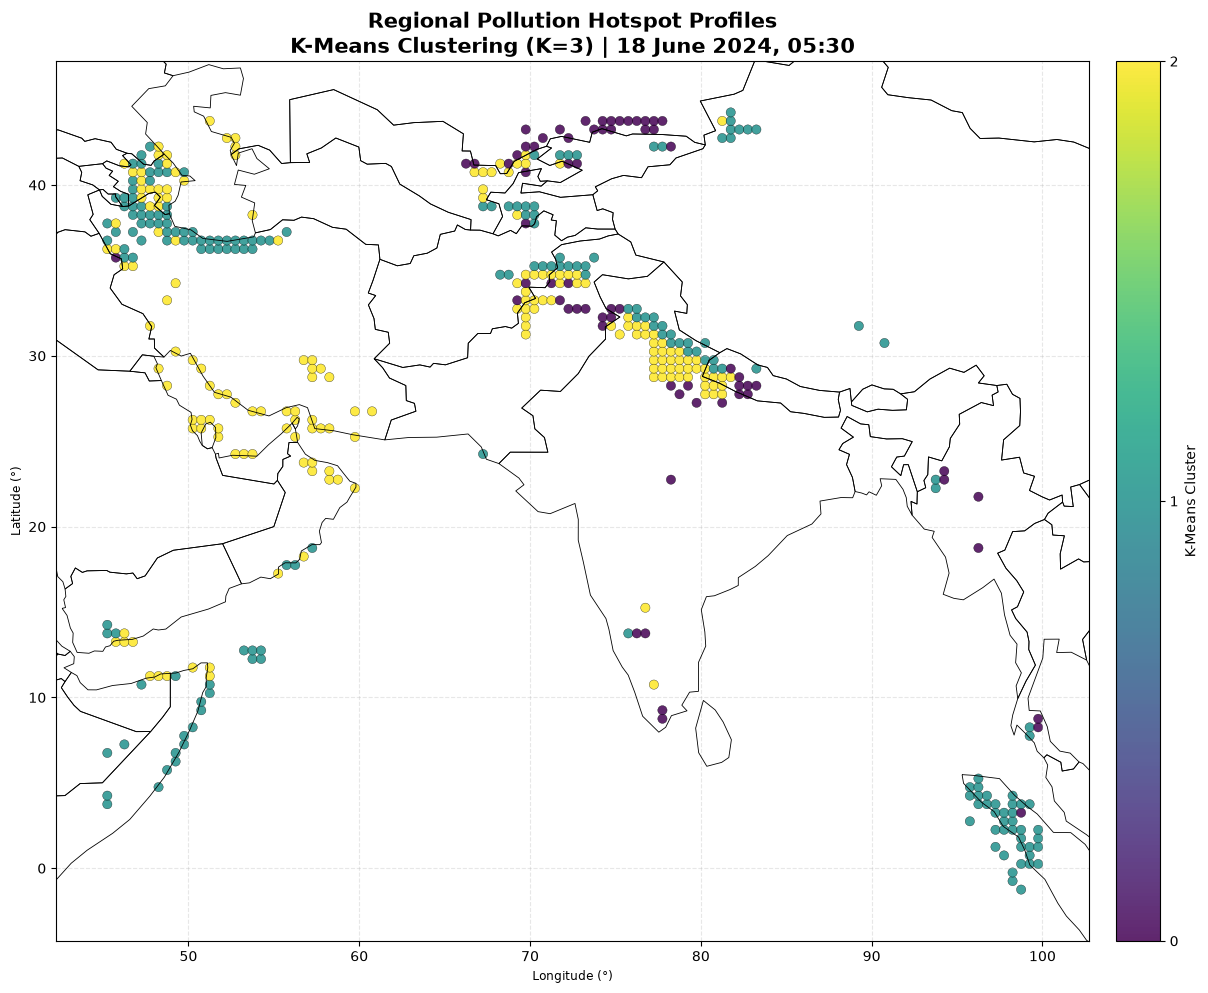

Final map saved to: c:\Users\Hp\OneDrive\Desktop\Regional Pollution Hotspot Profiles from Satellite-Derived Environmental Features\regional_cluster_map_0530.png


In [59]:

# Project directory
project_folder = PROJECT_DIR

# Ensure country boundaries use longitude/latitude coordinates
countries = countries.to_crs(epsg=4326)

# Plot
fig, ax = plt.subplots(figsize=(14, 10))

# Country boundaries
countries.boundary.plot(
    ax=ax,
    color="black",
    linewidth=0.6
)

# Regional cells, colored by cluster
scatter = ax.scatter(
    clustered_df["longitude"],
    clustered_df["latitude"],
    c=clustered_df["Cluster_K3"],
    cmap="viridis",
    s=45,
    alpha=0.85,
    edgecolors="black",
    linewidths=0.25
)

# Map extent based on the study data
ax.set_xlim(
    clustered_df["longitude"].min() - 3,
    clustered_df["longitude"].max() + 3
)
ax.set_ylim(
    clustered_df["latitude"].min() - 3,
    clustered_df["latitude"].max() + 3
)

# Labels and title
ax.set_xlabel("Longitude (°)")
ax.set_ylabel("Latitude (°)")
ax.set_title(
    "Regional Pollution Hotspot Profiles\n"
    "K-Means Clustering (K=3) | 18 June 2024, 05:30",
    fontsize=15,
    fontweight="bold"
)

# Cluster legend
colorbar = plt.colorbar(scatter, ax=ax, pad=0.02)
colorbar.set_label("K-Means Cluster")
colorbar.set_ticks([0, 1, 2])

ax.grid(True, linestyle="--", alpha=0.3)
ax.set_aspect("equal", adjustable="box")

plt.tight_layout()

# Save final map
output_path = project_folder / "regional_cluster_map_0530.png"
plt.savefig(output_path, dpi=300, bbox_inches="tight")
plt.show()

print(f"Final map saved to: {output_path}")

NameError: name 'Line2D' is not defined

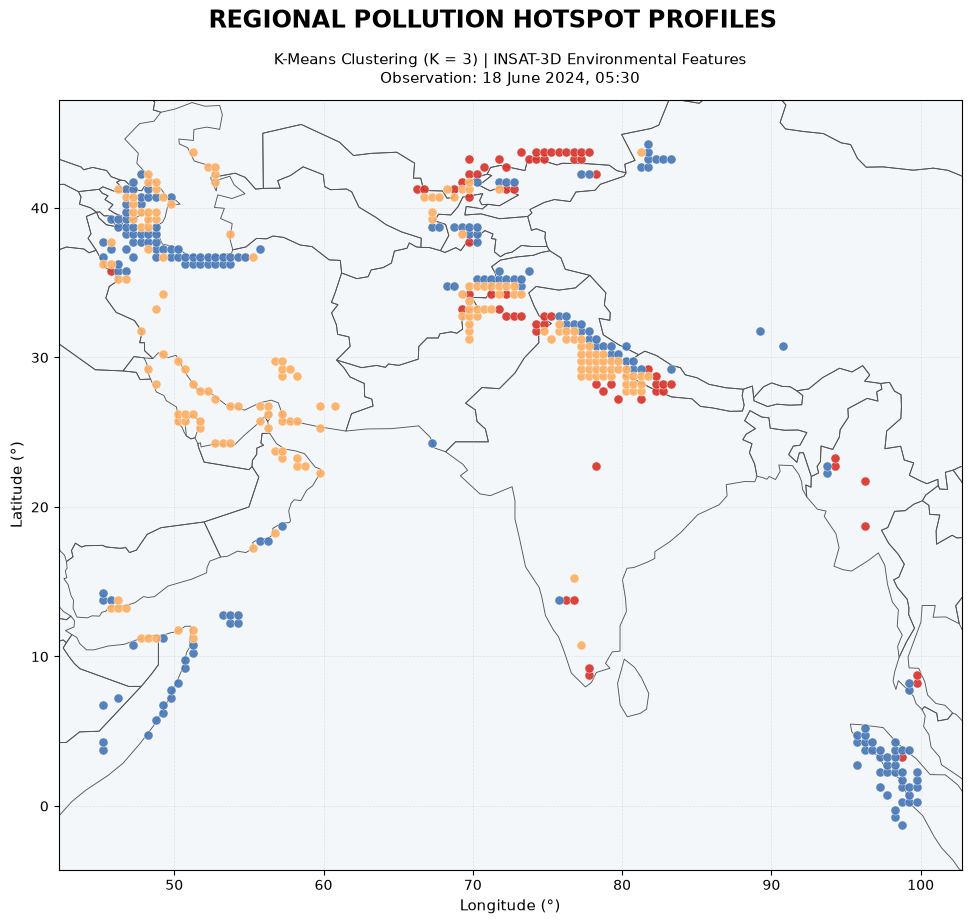

In [60]:

# Project directory
project_folder = PROJECT_DIR

# Distinct colors for categorical clusters
cluster_colors = {
    0: "#D73027",  # Red
    1: "#4575B4",  # Blue
    2: "#FDAE61"   # Orange
}

# Create figure
fig, ax = plt.subplots(figsize=(14, 10))

# Light background
ax.set_facecolor("#F4F7FA")

# Draw country boundaries
countries.boundary.plot(
    ax=ax,
    color="#555555",
    linewidth=0.65,
    zorder=1
)

# Plot each cluster separately
for cluster_id, color in cluster_colors.items():
    data = clustered_df[
        clustered_df["Cluster_K3"] == cluster_id
    ]

    ax.scatter(
        data["longitude"],
        data["latitude"],
        color=color,
        s=43,
        alpha=0.9,
        edgecolors="white",
        linewidths=0.35,
        label=f"Cluster {cluster_id} (n={len(data)})",
        zorder=2
    )

# Geographic extent
ax.set_xlim(
    clustered_df["longitude"].min() - 3,
    clustered_df["longitude"].max() + 3
)
ax.set_ylim(
    clustered_df["latitude"].min() - 3,
    clustered_df["latitude"].max() + 3
)

# Titles
fig.suptitle(
    "REGIONAL POLLUTION HOTSPOT PROFILES",
    fontsize=17,
    fontweight="bold",
    y=0.97
)

ax.set_title(
    "K-Means Clustering (K = 3) | INSAT-3D Environmental Features\n"
    "Observation: 18 June 2024, 05:30",
    fontsize=11,
    pad=12
)

# Axes
ax.set_xlabel("Longitude (°)", fontsize=11)
ax.set_ylabel("Latitude (°)", fontsize=11)
ax.grid(
    True,
    linestyle="--",
    linewidth=0.5,
    alpha=0.3
)

# Categorical legend
legend_handles = [
    Line2D(
        [0], [0],
        marker="o",
        color="w",
        markerfacecolor=color,
        markeredgecolor="white",
        markersize=9,
        label=f"Cluster {cluster_id} (n={len(clustered_df[clustered_df['Cluster_K3'] == cluster_id])})"
    )
    for cluster_id, color in cluster_colors.items()
]

ax.legend(
    handles=legend_handles,
    title="Regional Clusters",
    loc="lower left",
    frameon=True,
    framealpha=0.95
)

# Footnote
fig.text(
    0.5,
    0.015,
    "Clusters derived from mean AOD and mean land surface temperature. "
    "Clusters indicate environmental profiles, not confirmed ground-level pollution.",
    ha="center",
    fontsize=8,
    color="#444444"
)

# Save high-resolution map
output_path = project_folder / "regional_cluster_map_0530.png"

plt.tight_layout(rect=[0.02, 0.045, 0.98, 0.94])
plt.savefig(
    output_path,
    dpi=300,
    bbox_inches="tight",
    facecolor="white"
)

plt.show()

print(f"Final map saved to: {output_path}")

In [61]:
profile_path = DATA_DIR / "cluster_profiles_0530.csv"

cluster_profile.to_csv(profile_path, index=False)

print("Cluster profile table saved to:", profile_path)
print(cluster_profile)

Cluster profile table saved to: c:\Users\Hp\OneDrive\Desktop\Regional Pollution Hotspot Profiles from Satellite-Derived Environmental Features\data\processed\cluster_profiles_0530.csv
           AOD_mean                  LST_mean                   Rainfall_mean  \
               mean  median     std      mean    median     std          mean   
Cluster_K3                                                                      
0            1.3029  1.2165  0.4195  320.2201  321.6117  6.8261        0.0001   
1            0.3686  0.3163  0.2205  307.9223  308.6230  4.0635        0.0000   
2            0.4406  0.4294  0.1838  317.9759  317.6173  3.4697        0.0000   

                          Rainfall_positive_pct                Smoke_count  \
           median     std                  mean median     std        mean   
Cluster_K3                                                                   
0             0.0  0.0006                0.1668    0.0  1.3650      0.0000   
1             0.0

In [62]:
# Create a clean cluster summary from the existing clustered dataset

cluster_summary_clean = (
    clustered_df.groupby("Cluster_K3")
    .agg(
        Number_of_Cells=("Cluster_K3", "size"),
        Mean_AOD=("AOD_mean", "mean"),
        Median_AOD=("AOD_mean", "median"),
        Mean_LST_K=("LST_mean", "mean"),
        Median_LST_K=("LST_mean", "median"),
        Mean_Rainfall=("Rainfall_mean", "mean"),
        Mean_Smoke_Count=("Smoke_count", "mean"),
        Mean_Fire_Count=("Fire_count", "mean")
    )
    .round(4)
    .reset_index()
)

cluster_summary_clean["Percentage"] = (
    cluster_summary_clean["Number_of_Cells"]
    / len(clustered_df) * 100
).round(2)

# Arrange columns
cluster_summary_clean = cluster_summary_clean[
    [
        "Cluster_K3",
        "Number_of_Cells",
        "Percentage",
        "Mean_AOD",
        "Median_AOD",
        "Mean_LST_K",
        "Median_LST_K",
        "Mean_Rainfall",
        "Mean_Smoke_Count",
        "Mean_Fire_Count"
    ]
]

# Save
summary_path = project_folder / "cluster_summary_clean_0530.csv"
cluster_summary_clean.to_csv(summary_path, index=False)

print(cluster_summary_clean.to_string(index=False))
print(f"\nSaved to: {summary_path}")

 Cluster_K3  Number_of_Cells  Percentage  Mean_AOD  Median_AOD  Mean_LST_K  Median_LST_K  Mean_Rainfall  Mean_Smoke_Count  Mean_Fire_Count
          0               67       15.58    1.3029      1.2165    320.2201      321.6117         0.0001            0.0000           0.0000
          1              189       43.95    0.3686      0.3163    307.9223      308.6230         0.0000            0.0476           0.0000
          2              174       40.47    0.4406      0.4294    317.9759      317.6173         0.0000            0.0057           0.0115

Saved to: c:\Users\Hp\OneDrive\Desktop\Regional Pollution Hotspot Profiles from Satellite-Derived Environmental Features\cluster_summary_clean_0530.csv


In [63]:
# Check the final dataset and cluster assignments

print("Total regional cells:", len(clustered_df))
print("\nCluster sizes:")
print(clustered_df["Cluster_K3"].value_counts().sort_index())

print("\nMissing values in clustering features:")
print(
    clustered_df[["AOD_mean", "LST_mean"]]
    .isna()
    .sum()
)

print("\nUnique cluster labels:")
print(sorted(clustered_df["Cluster_K3"].unique()))

Total regional cells: 430

Cluster sizes:
Cluster_K3
0     67
1    189
2    174
Name: count, dtype: int64

Missing values in clustering features:
AOD_mean    0
LST_mean    0
dtype: int64

Unique cluster labels:
[np.int64(0), np.int64(1), np.int64(2)]


In [64]:
from pathlib import Path

project_folder = PROJECT_DIR

important_files = [
    "01_AOD_Data_Preparation.ipynb",
    "02_Clustering_Analysis.ipynb",
    "final_regional_dataset_0530.csv",
    "clustered_regional_dataset_0530.csv",
    "cluster_profiles_0530.csv",
    "cluster_summary_clean_0530.csv",
    "regional_cluster_map_0530.png",
    "AOD_vs_LST_clusters_0530.png"
]

print("FINAL PROJECT FILE CHECK\n")

for filename in important_files:
    file_path = project_folder / filename

    if file_path.exists():
        size_kb = file_path.stat().st_size / 1024
        print(f"OK      | {filename} | {size_kb:.1f} KB")
    else:
        print(f"MISSING | {filename}")

FINAL PROJECT FILE CHECK

MISSING | 01_AOD_Data_Preparation.ipynb
MISSING | 02_Clustering_Analysis.ipynb
MISSING | final_regional_dataset_0530.csv
MISSING | clustered_regional_dataset_0530.csv
OK      | cluster_profiles_0530.csv | 0.6 KB
OK      | cluster_summary_clean_0530.csv | 0.3 KB
OK      | regional_cluster_map_0530.png | 880.4 KB
OK      | AOD_vs_LST_clusters_0530.png | 433.7 KB
